# Dr.Copper v2 - Phase 5: Backtesting

In [2]:
import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import display

import dr_copper_v2 as dc
from dr_copper_v2.data_loader import ROOT

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].scale = 2

warnings.filterwarnings("ignore")

## 1 - Load development inputs

Load prepared CPER closes, Data2 forecasts and the frozen XGBoost configuration. Data3 remains reserved until the trading procedure is frozen.

In [3]:
import json

data_dir = ROOT / "data" / "processed"
raw = pd.read_parquet(data_dir / "raw_development.parquet")
xgb_predictions = pd.read_parquet(
    data_dir / "direction" / "xgb_predictions_development.parquet"
)
selected_config = json.loads(
    (data_dir / "direction" / "selected_direction_config.json").read_text(
        encoding="utf-8"
    )
)
cper_close = raw["copper"]

display(xgb_predictions.join(cper_close.rename("close")).head())

,label_end,direction,fold,model_output,prediction,close
date,,,,,,
2017-01-03,2017-01-10,1,2017-01,0.412912,0,16.240000
2017-01-04,2017-01-11,1,2017-01,0.455245,0,16.639999
2017-01-05,2017-01-12,1,2017-01,0.354471,0,16.480000
2017-01-06,2017-01-13,1,2017-01,0.410140,0,16.469999
2017-01-09,2017-01-17,1,2017-01,0.433498,0,16.590000


**1,510 forecasts across 72 months; 1,505 available labels.** Keep the five terminal forecasts: missing outcomes do not mean missing signals.

## 2 - Daily long/cash strategy

**Up = long; non-up = cash.** Forecast after close t; execute at close t+1. Repeated up signals retain one position. Start in cash and liquidate at the last close.

In [4]:
strategy = xgb_predictions[["prediction"]].join(cper_close.rename("close"))
strategy["target_long"] = strategy["prediction"].shift(1, fill_value=0)
strategy.loc[strategy.index[-1], "target_long"] = 0

strategy.tail()

,prediction,close,target_long
date,,,
2022-12-23,1,23.059999,1
2022-12-27,1,23.020000,1
2022-12-28,1,23.160000,1
2022-12-29,1,23.160000,1
2022-12-30,1,23.090000,0


`target_long` is the desired position **after that row's close**: 1 = long, 0 = cash. It applies to the following return interval.

### Candidate rules

| XGBoost rule | Entry | Exit |
|---|---|---|
| Daily | Up | Non-up |
| Confirmation | Two consecutive up forecasts | Two consecutive non-up forecasts |

**Benchmarks:** SMA 50/200, CPER buy-and-hold and assumed risk-free cash. Every decision executes at the next close; SMA uses earlier saved history for warm-up.

In [5]:
sma_long = (cper_close.rolling(50).mean() > cper_close.rolling(200).mean()).reindex(
    strategy.index
)

targets = pd.DataFrame(index=strategy.index)
for rule in ["daily", "confirmation"]:
    targets[f"XGBoost {rule}"] = dc.long_cash_targets(strategy["prediction"], rule=rule)
targets["SMA 50/200"] = dc.long_cash_targets(sma_long)
targets["CPER buy-and-hold"] = dc.long_cash_targets([1] * len(strategy))

display(targets.tail())

,XGBoost daily,XGBoost confirmation,SMA 50/200,CPER buy-and-hold
date,,,,
2022-12-23,1,1,0,1
2022-12-27,1,1,0,1
2022-12-28,1,1,0,1
2022-12-29,1,1,0,1
2022-12-30,0,0,0,0


## 3 - Data2 backtest

### Risk-free cash return

**Assume a constant 2% effective annual return**, accrued on calendar days. This is an illustrative cash-rate scenario, not the historical Treasury return. Apply the same rate to uninvested strategy cash; the flat Cash line remains the zero-interest reference.

In [6]:
risk_free_rate = 0.02
risk_free = pd.DataFrame(index=strategy.index)
risk_free["cash_return"] = (1 + risk_free_rate) ** (
    risk_free.index.to_series().diff().dt.days.fillna(0) / 365
) - 1

**At 2% annually, Data2 cash grows by ~12.6%.** Interest accrues on the cash balance held over each preceding interval.

### Run the backtest

**$100,000; commission $0.005/share; 5 bp slippage per side.** Buy fills exceed Close; sell fills are below Close. Whole shares, no leverage, same sizing and liquidation for every rule. Uninvested cash earns the assumed 2% annual cash rate.

**100% entry allocation only:** invest available cash including commission, rounded down to whole shares. No rebalancing while long. Use the same sizing for SMA and buy-and-hold.

In [7]:
initial_cash = 100_000
commission_per_share = 0.005
slippage_bps = 5

backtest_frame = strategy[["close"]].join(risk_free[["cash_return"]])
results = {
    name: dc.backtest_long_cash(
        backtest_frame.assign(target_long=targets[name]),
        initial_cash=initial_cash,
        commission_per_share=commission_per_share,
        slippage_bps=slippage_bps,
    )
    for name in targets.columns
}

risk_free_equity = initial_cash * (1 + risk_free["cash_return"]).cumprod()

In [8]:
comparison = dc.backtest_summary(results, initial_cash)
comparison.loc["Risk-free cash"] = {
    "Net return": f"{risk_free_equity.iloc[-1] / initial_cash - 1:.2%}",
    "Max drawdown": f"{(risk_free_equity / risk_free_equity.cummax() - 1).min():.2%}",
    "Fills": "0",
    "Commission (USD)": "0.00",
    "Slippage (USD)": "0.00",
    "Final equity (USD)": f"{risk_free_equity.iloc[-1]:,.2f}",
}
display(comparison)

,Net return,Max drawdown,Fills,Commission (USD),Slippage (USD),Final equity (USD)
Strategy,,,,,,
XGBoost daily,18.33%,-27.65%,382,"9,984.61","20,025.45","118,328.83"
XGBoost confirmation,53.86%,-30.42%,116,"3,449.68","6,647.90","153,863.02"
SMA 50/200,42.56%,-25.21%,10,298.11,597.17,"142,557.00"
CPER buy-and-hold,38.56%,-38.42%,2,60.05,119.29,"138,558.62"
Risk-free cash,12.60%,0.00%,0,0.00,0.00,"112,597.91"


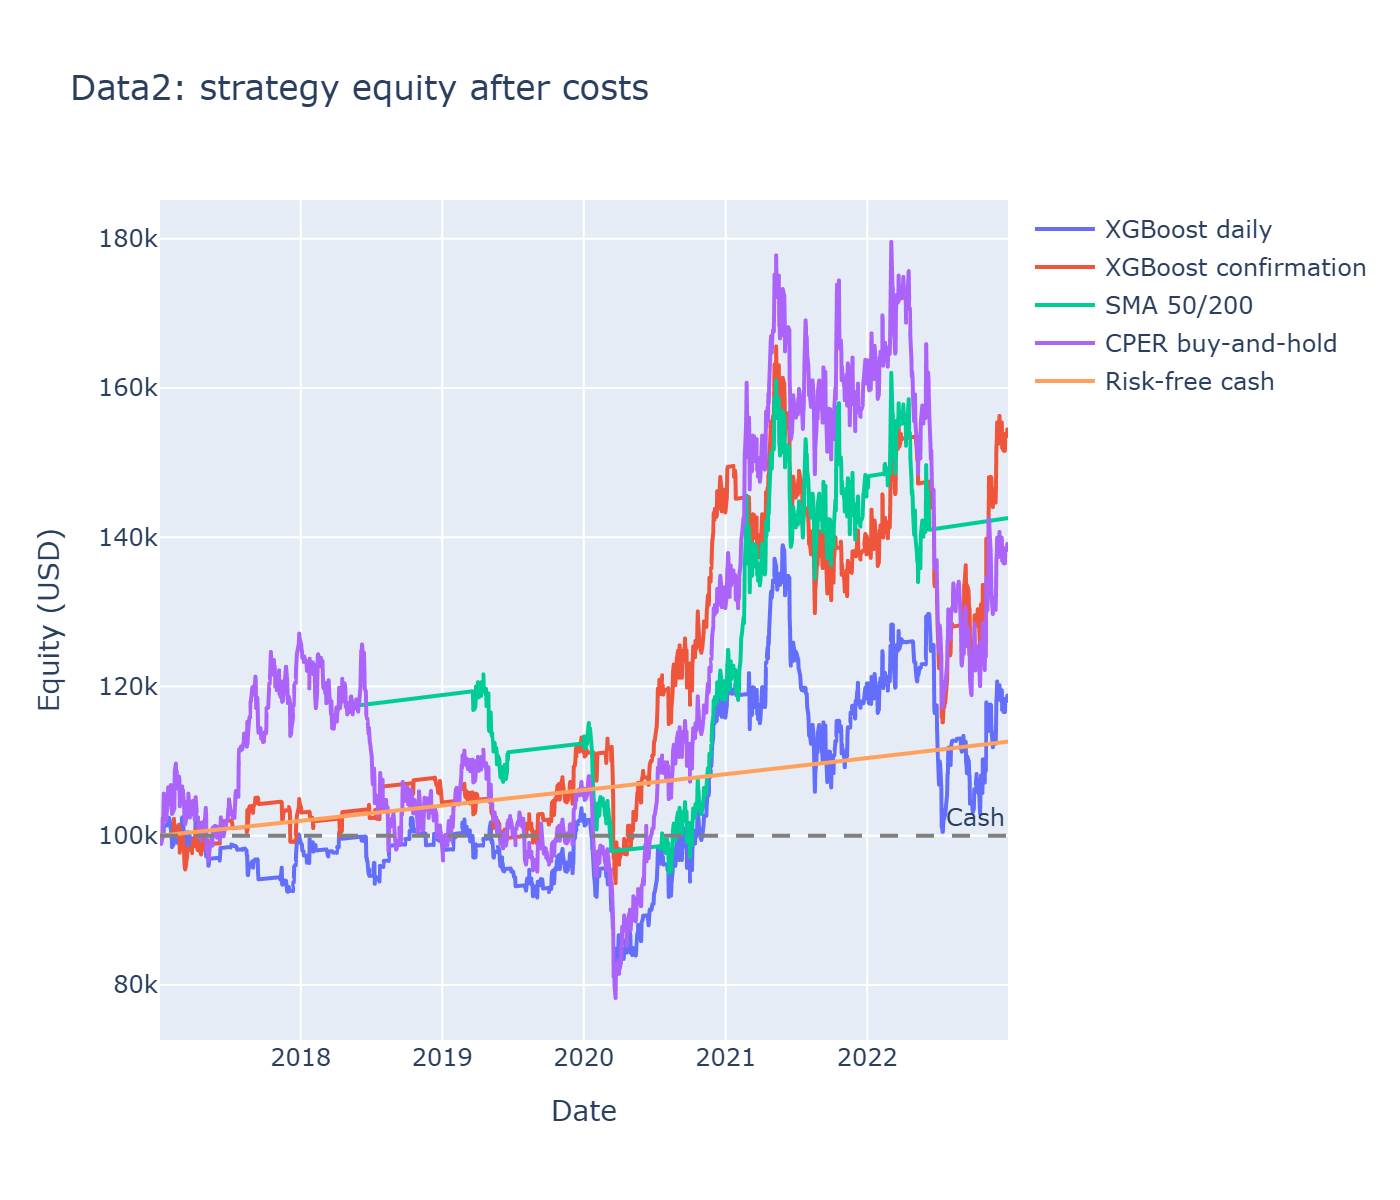

In [9]:
import plotly.express as px

equity = pd.DataFrame({name: result["equity"] for name, result in results.items()})
equity["Risk-free cash"] = risk_free_equity
fig = px.line(
    equity,
    title="Data2: strategy equity after costs",
    labels={"value": "Equity (USD)", "variable": "", "date": "Date"},
)
fig.add_hline(
    y=initial_cash, line_dash="dash", line_color="gray", annotation_text="Cash"
)
fig.update_layout(hovermode="x unified", height=600)
fig.show()

## 4 - Development reports

QuantStats uses the engine's **net returns**, the same CPER buy-and-hold benchmark, 2% annual risk-free rate and 252 periods/year. Keep all evaluation dates, including initial cash intervals. Report win rates describe return periods, not completed trades. These remain Data2 development results.

In [10]:
import quantstats as qs

report_dir = ROOT / "reports"
report_dir.mkdir(exist_ok=True)

for rule in ["daily", "confirmation"]:
    qs.reports.html(
        results[f"XGBoost {rule}"]["net_return"],
        benchmark=results["CPER buy-and-hold"]["net_return"],
        rf=risk_free_rate,
        periods_per_year=252,
        match_dates=False,
        strategy_title=f"XGBoost {rule}",
        benchmark_title="CPER buy-and-hold",
        title=f"Data2: XGBoost {rule} after costs",
        output=str(report_dir / f"phase5_{rule}_development.html"),
    )

[Daily report](../reports/phase5_daily_development.html) | [Confirmation report](../reports/phase5_confirmation_development.html)

**Data2 interpretation**

- **Return:** confirmation **53.86%**, SMA **42.56%**, buy-and-hold **38.56%**, daily **18.33%**.
- **CAGR:** confirmation **7.46%**, SMA **6.10%**, buy-and-hold **5.59%**, daily **2.85%** (252 periods/year).
- **Trading costs:** confirmation makes **116 fills** versus daily's **382**; commission plus slippage totals about **$10,098 vs $30,010**.
- **Risk:** confirmation's drawdown is **30.42%**, worse than SMA's **25.21%**. Its one-day 95% normal-model VaR/CVaR are **1.70% / 2.14%**. Hull (11th Global edition, section 22.1, pp. 514-516) defines VaR as a loss threshold and CVaR as the average loss beyond it; neither caps losses.
- **Conclusion:** confirmation leads this development comparison. Repeated Data2 selection limits the claim; the frozen procedure still needs Data3 evaluation.

## 5 - Final evaluation: Data3

**January 2023-October 2026; no retuning.**

In [11]:
import yfinance as yf

final_raw = dc.fetch_raw(start="2023-01-01", end="2026-11-01")
final_raw.to_parquet(data_dir / "raw_final.parquet")

final_outcomes = (
    yf.download(
        "CPER",
        start="2026-11-01",
        end="2026-11-15",
        auto_adjust=False,
        multi_level_index=False,
        progress=False,
    )[["Close"]]
    .head(5)
    .rename(columns={"Close": "copper"})
)
final_outcomes.index.name = "date"
final_outcomes.to_parquet(data_dir / "cper_label_outcomes_final.parquet")

In [12]:
all_raw = pd.concat([raw, final_raw])
all_features = dc.add_macro_changes(dc.fetch_features(all_raw)).loc["2012-01-01":]
final_splits = pd.DataFrame(
    {
        "train_start": train.index[0],
        "train_end": train.index[-1],
        "test_start": forecast.index[0],
        "test_end": forecast.index[-1],
    }
    for train, forecast in dc.walk_forward_split(
        all_features, test_start="2023-01-01", test_end="2026-11-01"
    )
)
final_garch, final_garch_refits = dc.forecast_garch_models(
    all_features["copper_ret1d"],
    final_splits,
    distributions={"Gaussian": "normal"},
)
garch_history = pd.concat(
    [
        pd.read_parquet(data_dir / "garch" / "gaussian_forecasts_development.parquet"),
        final_garch.set_index("date"),
    ]
)
final_inputs = all_features.join(garch_history[["volatility_1d", "volatility_5d"]]).loc[
    "2013-01-01":, selected_config["feature_columns"]
]

### Monthly walk-forward forecasts

Use the selected 21 columns directly; no PCA/KMeans refits are needed for this model. GARCH training features retain their original causal dates. Filter labels by their actual end dates at every monthly cutoff.

In [13]:
final_labels = dc.direction_target(
    pd.concat([all_raw["copper"], final_outcomes["copper"]])
)
final_folds = {}
for split in final_splits.itertuples():
    train = final_labels.loc[final_inputs.index].loc[
        split.train_start : split.train_end
    ]
    train = train.loc[
        train["direction"].notna() & train["label_end"].le(split.train_end)
    ]
    forecast = final_labels.loc[split.test_start : split.test_end]
    final_folds[split.test_start.strftime("%Y-%m")] = {
        "train_labels": train,
        "forecast_labels": forecast,
        "inputs": {
            "train": {selected_config["feature_group"]: final_inputs.loc[train.index]},
            "forecast": {
                selected_config["feature_group"]: final_inputs.loc[forecast.index]
            },
        },
    }
final_predictions = dc.forecast_xgb(
    final_folds, selected_config["feature_group"], selected_config["xgb_params"]
)
final_predictions.to_parquet(data_dir / "direction" / "xgb_predictions_final.parquet")

final_benchmarks = dc.forecast_direction_benchmarks(
    final_folds,
    selected_config["feature_group"],
    {"L2 logistic": {"C": 10.0, "max_iter": 2000}},
)
display(
    pd.DataFrame(
        {
            "XGBoost": final_predictions["prediction"],
            "Always-up": final_benchmarks["always_up"],
            "L2 logistic": final_benchmarks["L2 logistic"],
        }
    )
    .eq(final_predictions["direction"], axis=0)
    .mean()
    .to_frame("Data3 accuracy")
)

,Data3 accuracy
XGBoost,0.497399
Always-up,0.548387
L2 logistic,0.519251


### Same trading procedure

Apply the existing daily/confirmation rules, SMA 50/200 and buy-and-hold with the same commission, slippage, full entry allocation and 2% assumed cash rate.

In [14]:
final_strategy = final_predictions[["prediction"]].join(
    all_raw["copper"].rename("close")
)
final_targets = pd.DataFrame(index=final_strategy.index)
for rule in ["daily", "confirmation"]:
    final_targets[f"XGBoost {rule}"] = dc.long_cash_targets(
        final_strategy["prediction"], rule=rule
    )
final_targets["SMA 50/200"] = dc.long_cash_targets(
    (
        all_raw["copper"].rolling(50).mean() > all_raw["copper"].rolling(200).mean()
    ).reindex(final_strategy.index)
)
final_targets["CPER buy-and-hold"] = dc.long_cash_targets([1] * len(final_strategy))
final_cash_return = (1 + risk_free_rate) ** (
    final_strategy.index.to_series().diff().dt.days.fillna(0) / 365
) - 1
final_frame = final_strategy[["close"]].assign(cash_return=final_cash_return)
final_results = {
    name: dc.backtest_long_cash(
        final_frame.assign(target_long=final_targets[name]),
        initial_cash=initial_cash,
        commission_per_share=commission_per_share,
        slippage_bps=slippage_bps,
    )
    for name in final_targets.columns
}
final_risk_free_equity = initial_cash * (1 + final_cash_return).cumprod()
final_comparison = dc.backtest_summary(final_results, initial_cash)
final_comparison.loc["Risk-free cash"] = {
    "Net return": f"{final_risk_free_equity.iloc[-1] / initial_cash - 1:.2%}",
    "Max drawdown": f"{(final_risk_free_equity / final_risk_free_equity.cummax() - 1).min():.2%}",
    "Fills": "0",
    "Commission (USD)": "0.00",
    "Slippage (USD)": "0.00",
    "Final equity (USD)": f"{final_risk_free_equity.iloc[-1]:,.2f}",
}
display(final_comparison)

,Net return,Max drawdown,Fills,Commission (USD),Slippage (USD),Final equity (USD)
Strategy,,,,,,
XGBoost daily,8.57%,-27.71%,182,"3,141.52","9,010.20","108,572.86"
XGBoost confirmation,36.54%,-29.33%,80,"1,579.67","4,561.22","136,537.24"
SMA 50/200,37.65%,-24.77%,8,149.03,420.85,"137,649.98"
CPER buy-and-hold,71.84%,-24.77%,2,44.10,135.94,"171,840.92"
Risk-free cash,7.87%,0.00%,0,0.00,0.00,"107,868.02"


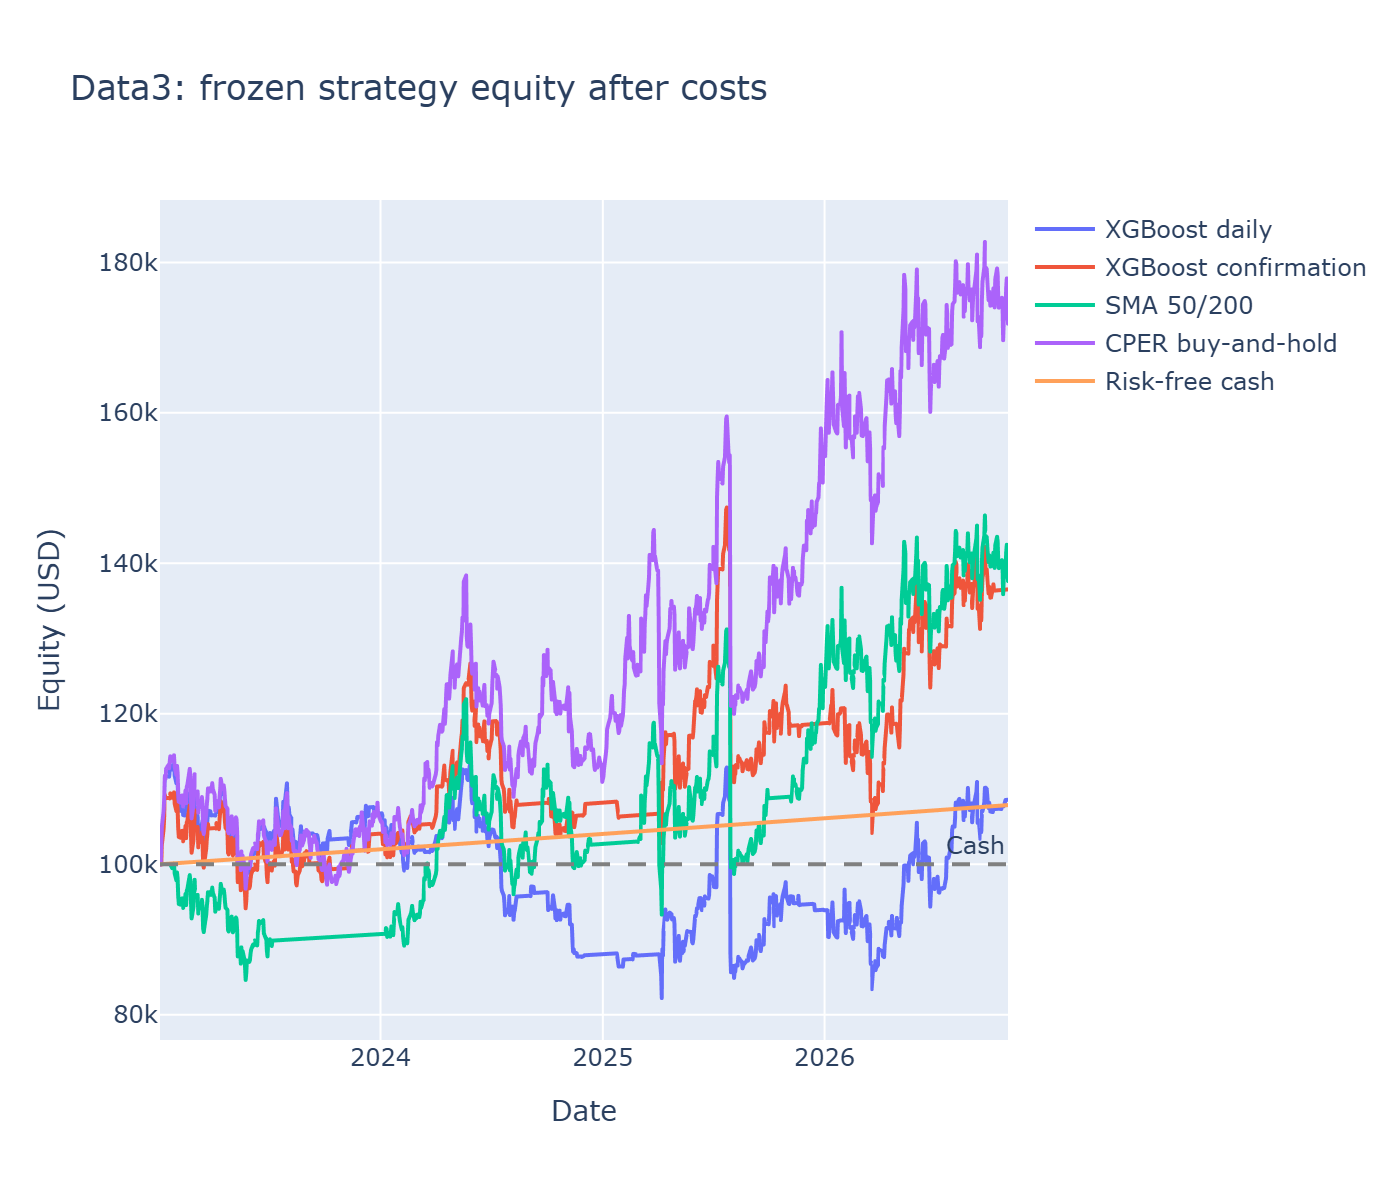

In [15]:
final_equity = pd.DataFrame(
    {name: result["equity"] for name, result in final_results.items()}
)
final_equity["Risk-free cash"] = final_risk_free_equity
final_fig = px.line(
    final_equity,
    title="Data3: frozen strategy equity after costs",
    labels={"value": "Equity (USD)", "variable": "", "date": "Date"},
)
final_fig.add_hline(
    y=initial_cash, line_dash="dash", line_color="gray", annotation_text="Cash"
)
final_fig.update_layout(hovermode="x unified", height=600)
final_fig.show()

In [16]:
import quantstats as qs

for rule in ["daily", "confirmation"]:
    qs.reports.html(
        final_results[f"XGBoost {rule}"]["net_return"],
        benchmark=final_results["CPER buy-and-hold"]["net_return"],
        rf=risk_free_rate,
        periods_per_year=252,
        match_dates=False,
        strategy_title=f"XGBoost {rule}",
        benchmark_title="CPER buy-and-hold",
        title=f"Data3: XGBoost {rule} after costs",
        output=str(report_dir / f"phase5_{rule}_final.html"),
    )

[Daily final report](../reports/phase5_daily_final.html) | [Confirmation final report](../reports/phase5_confirmation_final.html)

**Data3 interpretation**

- **Direction accuracy:** XGBoost **49.74%**, always-up **54.84%**, L2 logistic **51.93%** on 961 origins.
- **Return:** confirmation **36.54%**, SMA **37.65%**, buy-and-hold **71.84%**, daily **8.57%**.
- **CAGR:** confirmation **8.51%**, SMA **8.74%**, buy-and-hold **15.25%**, daily **2.18%** (252 periods/year).
- **Trading costs:** confirmation makes **80 fills** versus daily's **182**, costing about **$6,141 vs $12,152**. **Costs do not explain the full shortfall:** with zero commission and slippage, confirmation returns **44.11%**, daily **22.74%**, and buy-and-hold **72.07%**.
- **Risk:** confirmation's drawdown is **29.33%**, worse than SMA and buy-and-hold at **24.77%**. Its one-day 95% normal-model VaR/CVaR are **2.21% / 2.78%**.
- **Conclusion:** the development advantage did not generalize. The selected pipeline does not demonstrate incremental predictive or trading value on this final path.